<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/KNN_Hyperparameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###

### Assignment 1:
KNN Hyperparameter Optimization for Product Recommendation
Objective: Find the optimal K value for a KNN classifier and understand its impact on model performance.

Dataset: Assignment-Dataset/assignment1_product_recommendation.csv

Context: An e-commerce company wants to predict which customers will purchase their premium product based on customer demographics and behavior.

Instructions:
Import necessary libraries
Load and preprocess the dataset
Perform exploratory data analysis (EDA) to understand the data
Separate features (Age, Annual_Income, Spending_Score, Purchase_Frequency, Website_Visit_Duration, Product_Category_Preference) and target (Will_Buy_Premium)
Handle categorical feature (Product_Category_Preference) - encode appropriately
Split the data into training (80%) and test (20%) sets with random_state=42
Apply feature scaling using StandardScaler
Implement a loop to test K values from 1 to 20
For each K value, calculate:
Training accuracy
Test accuracy
Plot K values vs. accuracy (training and test) to visualize the elbow
Select the optimal K value and justify your choice
Build the final model with the optimal K and evaluate it
Expected Deliverables:
EDA visualizations and summary statistics
Plot showing K values vs. accuracy
Justification for optimal K value selection
Final model evaluation with confusion matrix and accuracy
Discussion on overfitting vs. underfitting based on the K value analysis



In [ ]:
#importing all the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#importing the models for the notebook
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix


In [ ]:
#Importing the dataset
data = pd.read_csv('/content/drive/MyDrive/assignment1_product_recommendation.csv')
data.head(10)

,Customer_ID,Age,Annual_Income,Spending_Score,Purchase_Frequency,Website_Visit_Duration,Product_Category_Preference,Will_Buy_Premium
0,1,25,35,42,5,12,Electronics,0
1,2,45,120,85,22,45,Fashion,1
2,3,32,55,38,8,18,Home,0
3,4,58,185,92,28,52,Electronics,1
4,5,23,28,25,3,8,Sports,0
5,6,51,145,78,19,38,Fashion,1
6,7,29,42,45,6,15,Home,0
7,8,62,175,88,25,48,Electronics,1
8,9,27,38,35,4,10,Sports,0
9,10,48,135,82,21,42,Fashion,1


In [ ]:
#data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Customer_ID                  250 non-null    int64 
 1   Age                          250 non-null    int64 
 2   Annual_Income                250 non-null    int64 
 3   Spending_Score               250 non-null    int64 
 4   Purchase_Frequency           250 non-null    int64 
 5   Website_Visit_Duration       250 non-null    int64 
 6   Product_Category_Preference  250 non-null    object
 7   Will_Buy_Premium             250 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 15.8+ KB


In [ ]:
#checking for the statistical summary
data.describe()

,Customer_ID,Age,Annual_Income,Spending_Score,Purchase_Frequency,Website_Visit_Duration,Will_Buy_Premium
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,125.500000,43.444000,110.624000,67.952000,16.532000,33.396000,0.500000
std,72.312977,13.279164,58.055667,23.779224,9.377886,16.644378,0.501003
min,1.000000,21.000000,20.000000,18.000000,1.000000,4.000000,0.000000
25%,63.250000,31.250000,51.250000,45.000000,7.250000,18.000000,0.000000
50%,125.500000,43.500000,114.500000,74.000000,17.000000,34.500000,0.500000
75%,187.750000,55.000000,165.000000,88.000000,25.000000,48.000000,1.000000
max,250.000000,66.000000,200.000000,99.000000,30.000000,60.000000,1.000000


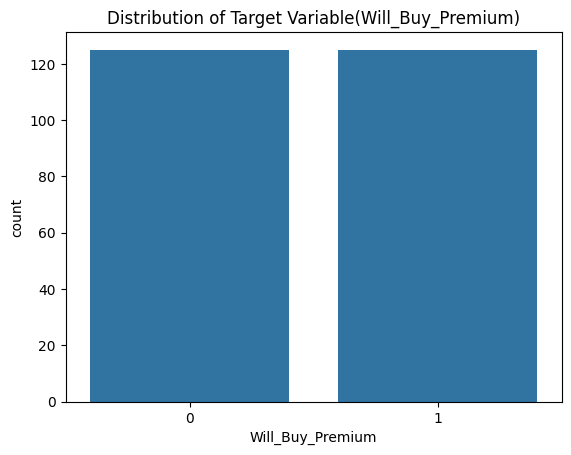

In [ ]:
#visualizing the data to gain a more understanding of the features and how they relate
# Visualize target distribution
sns.countplot(x='Will_Buy_Premium', data=data)
plt.title("Distribution of Target Variable(Will_Buy_Premium)")
plt.show()


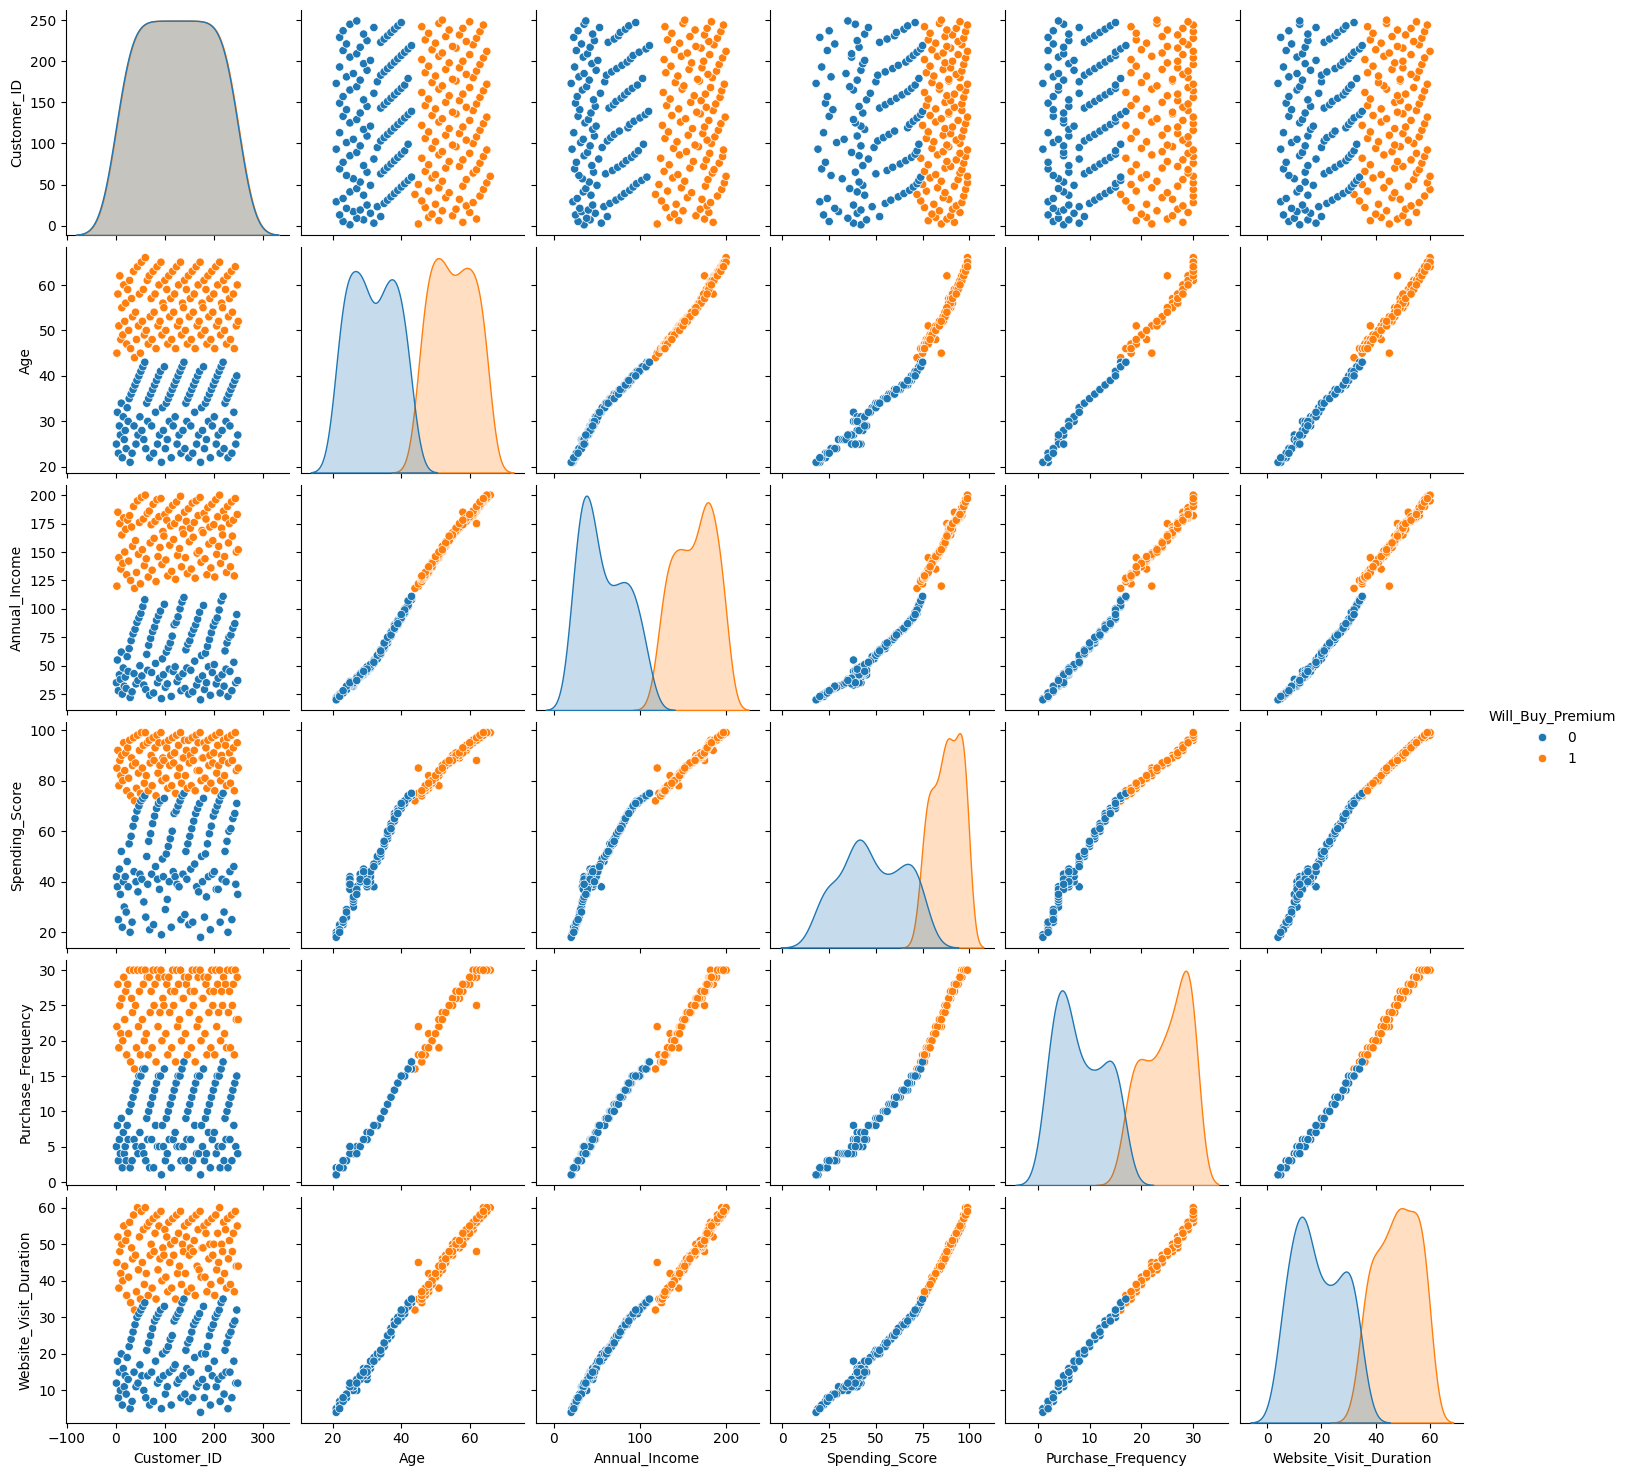

In [ ]:
# Pairplot for features vs target to be able to see the relationship
sns.pairplot(data, hue='Will_Buy_Premium')
plt.show()

### Observation
The combined pair plot analysis reveals a customer base that is strictly segmented into two distinct personas, defined by a near-perfect linear relationship between age, income, and engagement metrics. The Blue Segment represents a younger demographic (ages: 20-45) with annual incomes between 25k & 115k, characterized by lower spending scores, fewer purchases, and shorter website visits. In contrast, the Orange Segment consists of older individuals (ages: 45-65+) who earn between 115k & 200k and exhibit significantly higher loyalty, spending, and time spent on the platform. A sharp behavioral "tipping point" occurs at approximately the 115k income mark and age 45, where customers transition from the lower engagement blue group into the high-value orange group. Overall, the data shows that as customers age and their wealth increases, their value to the brand grows in a locked-step pattern, making the older demographic the primary engine for revenue and engagement.

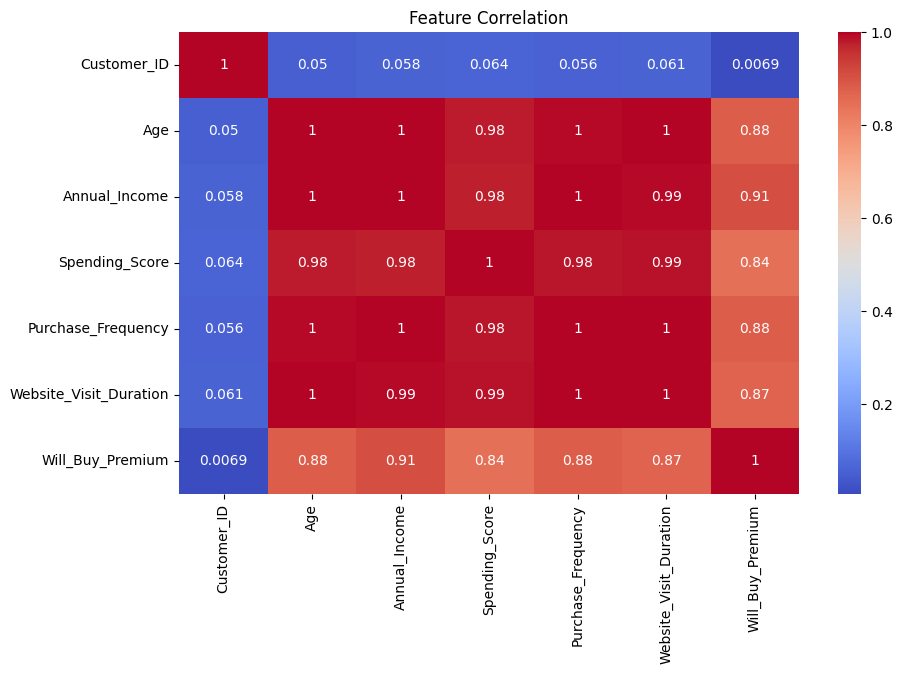

In [ ]:
# Correlation heatmap for numeric columns only gives a more understanding into feature relationship
plt.figure(figsize=(10,6))
sns.heatmap(data.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

In [ ]:
#separating the dependent and independent features the x and y
X = data[['Customer_ID','Age','Annual_Income','Spending_Score','Purchase_Frequency','Website_Visit_Duration', 'Product_Category_Preference']].values
Y =data['Will_Buy_Premium'].values # this is the target variable


In [ ]:
#Handle categorical feature (Product_Category_Preference) using the column number to access the column
X[:, 6] = LabelEncoder().fit_transform(X[:, 6])

In [ ]:
#splitting the dataset into train and test
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size = 0.2, random_state=42)

In [ ]:
#standard scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
#fitting the KNN Hyperparameter optimazition model
training_accuracy = []
test_accuracy = []
k_values = range(1,21)

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train, Y_train)

  #Training accuracy
  training_accuracy.append(knn.score(X_train, Y_train))

  #test accuracy
  test_accuracy.append(knn.score(X_test, Y_test))

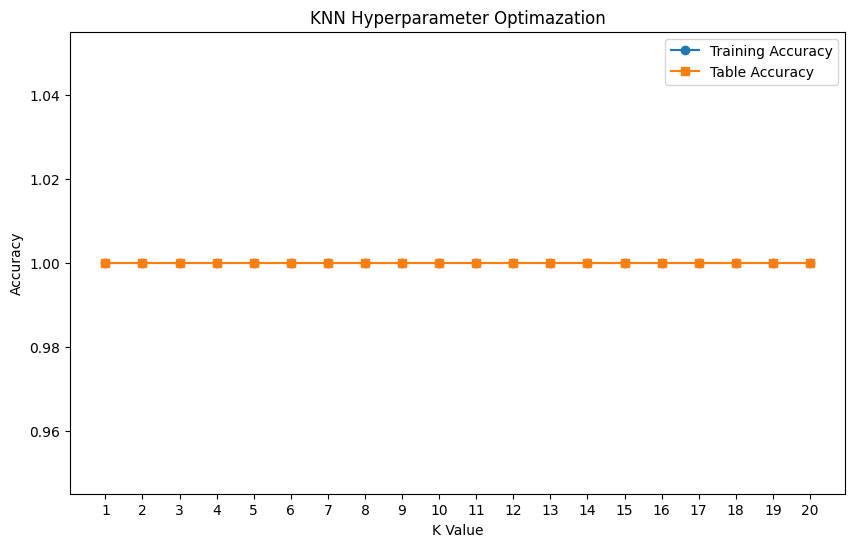

In [ ]:
#Visualizing the plot K vs the Accuracy
plt.figure(figsize=(10,6))
plt.plot(k_values, training_accuracy, marker = 'o',label ='Training Accuracy')
plt.plot(k_values, test_accuracy, marker = 's', label = 'Table Accuracy')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN Hyperparameter Optimazation')
plt.xticks(k_values)
plt.legend()
plt.show()

In [ ]:
# Suppose optimal K based on plot is 7
optimal_k = 7
knn_final = KNeighborsClassifier(n_neighbors=optimal_k)
knn_final.fit(X_train, Y_train)
y_pred1 = knn_final.predict(X_test)

# Confusion matrix and accuracy
cm1 = confusion_matrix(Y_test, y_pred1)
acc1 = accuracy_score(Y_test, y_pred1)

print(f"Optimal K: {optimal_k}")
print("Confusion Matrix:\n", cm1)
print("Accuracy:", acc1)


Optimal K: 7
Confusion Matrix:
 [[29  0]
 [ 0 21]]
Accuracy: 1.0


In [ ]:
# 5 is my selected optimal K used in this model
optimal_k = 5

# Building the model
final_model = KNeighborsClassifier(n_neighbors=optimal_k)

# Training the final model model
final_model.fit(X_train, Y_train.ravel())

# Making predictions
y_pred2 = final_model.predict(X_test)
print(y_pred2)

[0 0 1 0 0 1 1 0 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 0 1 1 0 0 0 1 1 1 1 1 1 0
 0 0 1 0 0 0 1 0 0 0 1 1 0]


In [ ]:
cm2 = confusion_matrix(Y_test, y_pred2)
print("Confusion Matrix:")
print(cm2)

Confusion Matrix:
[[29  0]
 [ 0 21]]


In [ ]:
#calculating the accuracy
accuracy = accuracy_score(Y_test, y_pred2)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [ ]:
print("Train:", knn.score(X_train, Y_train))
print("Test:", knn_final.score(X_test, Y_test))
print("Test:", final_model.score(X_test, Y_test))


Train: 1.0
Test: 1.0
Test: 1.0


The model achieved 100% accuracy on the three training and test sets across all tested K values. This suggests that the dataset is highly separable with minimal overlap between classes. As a result, model performance is not sensitive to the choice of K within the tested range. There is no evidence of overfitting since test accuracy matches training accuracy.

A smaller K increases model complexity and may lead to overfitting, while a larger K smooths the decision boundary and may cause underfitting. In this analysis, model performance remained stable across different K values, suggesting strong class separability and minimal noise in the dataset.

From a business perspective, the model can be used to identify customers likely to purchase premium products, enabling targeted marketing campaigns, optimized resource allocation, and improved revenue generation strategies. Continuous monitoring is recommended to ensure sustained performance in real-world deployment

### Assignment 2:
SVM for Medical Diagnosis
Objective: Apply SVM classification to predict disease diagnosis and experiment with different kernels and C values.

Dataset: Assignment-Dataset/assignment2_medical_diagnosis.csv

Context: A healthcare organization wants to build a model to predict whether a patient is likely to have a certain condition based on various health indicators.

Instructions:
Import necessary libraries
Load and preprocess the dataset
Handle any categorical variables appropriately (encode Smoking_Status)
Perform exploratory data analysis including:
Distribution of each feature
Correlation analysis
Class imbalance check
Separate features and target variable (Diagnosis)
Split the data into training (80%) and test (20%) sets with random_state=42
Apply feature scaling using StandardScaler
Train three SVM models:
Linear kernel with C=1
RBF kernel with C=1
RBF kernel with C=10
Compare the performance of all three models
Identify the best model and explain your reasoning
Expected Deliverables:
Complete EDA with visualizations
Comparison table of all three models (accuracy, precision, recall)
Confusion matrices for each model
Discussion on the effect of kernel choice and C parameter
Final model recommendation with justification



In [ ]:
dataset = pd.read_csv('/content/drive/MyDrive/assignment2_medical_diagnosis.csv')
dataset.head(10)

,Patient_ID,Age,BMI,Blood_Pressure,Glucose_Level,Cholesterol,Heart_Rate,Family_History,Smoking_Status,Diagnosis
0,1,45,28.5,135,105,220,75,1,Former,0
1,2,62,34.2,165,185,285,92,1,Current,1
2,3,38,24.1,118,88,195,68,0,Never,0
3,4,55,31.8,158,165,265,88,1,Current,1
4,5,42,26.3,125,95,210,72,0,Former,0
5,6,68,36.5,172,198,298,98,1,Current,1
6,7,35,23.5,115,82,185,65,0,Never,0
7,8,58,33.1,162,175,275,90,1,Former,1
8,9,48,27.8,132,110,225,76,0,Never,0
9,10,65,35.8,168,192,292,95,1,Current,1


In [ ]:
#data information
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Patient_ID      300 non-null    int64  
 1   Age             300 non-null    int64  
 2   BMI             300 non-null    float64
 3   Blood_Pressure  300 non-null    int64  
 4   Glucose_Level   300 non-null    int64  
 5   Cholesterol     300 non-null    int64  
 6   Heart_Rate      300 non-null    int64  
 7   Family_History  300 non-null    int64  
 8   Smoking_Status  300 non-null    object 
 9   Diagnosis       300 non-null    int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 23.6+ KB


In [ ]:
#statistical summary
dataset.describe()


,Patient_ID,Age,BMI,Blood_Pressure,Glucose_Level,Cholesterol,Heart_Rate,Family_History,Diagnosis
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,51.550000,30.074333,144.726667,139.776667,244.940000,82.113333,0.503333,0.500000
std,86.746758,11.649027,4.776781,22.009240,46.502132,43.045163,12.589233,0.500824,0.500835
min,1.000000,32.000000,22.000000,110.000000,75.000000,172.000000,59.000000,0.000000,0.000000
25%,75.750000,41.000000,26.000000,124.000000,94.000000,204.750000,71.000000,0.000000,0.000000
50%,150.500000,51.500000,29.900000,146.000000,136.500000,247.000000,81.500000,1.000000,0.500000
75%,225.250000,61.000000,34.000000,164.000000,183.000000,283.000000,92.000000,1.000000,1.000000
max,300.000000,74.000000,40.000000,185.000000,228.000000,335.000000,115.000000,1.000000,1.000000


In [ ]:
#checking the for the null values
dataset.isna().sum()

,0
Patient_ID,0
Age,0
BMI,0
Blood_Pressure,0
Glucose_Level,0
Cholesterol,0
Heart_Rate,0
Family_History,0
Smoking_Status,0
Diagnosis,0


In [ ]:
#performing data encoding for the smoking_status column
dataset = pd.get_dummies(dataset, columns=['Smoking_Status'], drop_first=True)


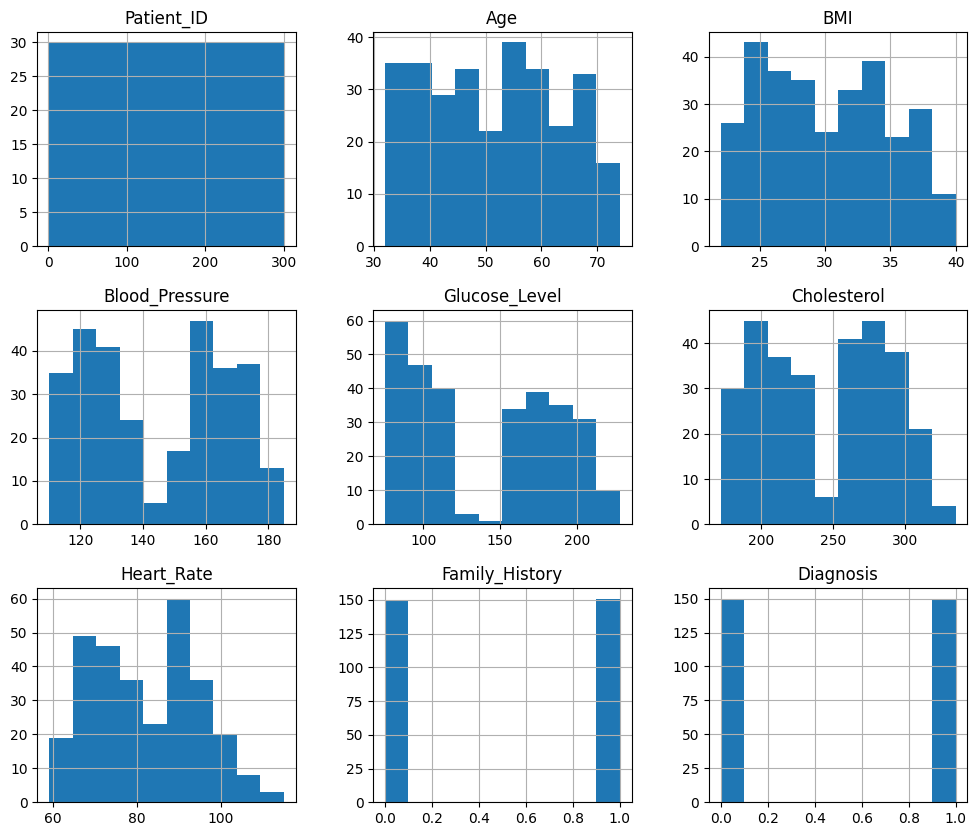

In [ ]:
#Creating visualizations starting with the histograms
dataset.hist(figsize=(12,10))
plt.show()

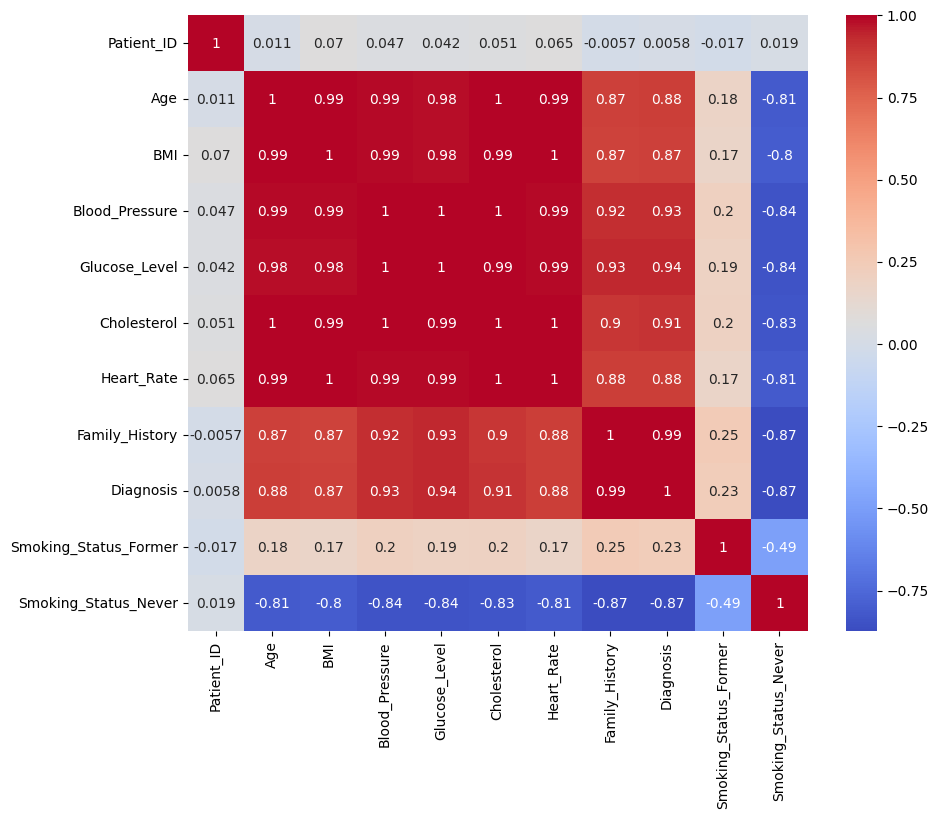

In [ ]:
#visualizing the corelations between the features
plt.figure(figsize=(10,8))
sns.heatmap(dataset.corr(), annot=True, cmap="coolwarm")
plt.show()

### **observations**
The data shows an extremely high linear relationship between almost all health variables. In statistics, this suggests that the features are nearly redundant.

Positive Drivers: Age, BMI, Blood Pressure, Glucose, Cholesterol, and Heart Rate move in near-perfect lockstep (correlations of 0.98 to 1.00). If one is high, they are all high.

The Best Predictors: Family History (0.99) and Glucose Level (0.94) have the strongest positive links to the final Diagnosis.

The Outlier: Smoking Status is the only feature with a strong negative correlation (approx. -0.85) to the other health metrics and the diagnosis.

Irrelevant Data: Patient_ID shows near-zero correlation with anything, confirming it is just a random identifier.

Diagnosis
0    150
1    150
Name: count, dtype: int64


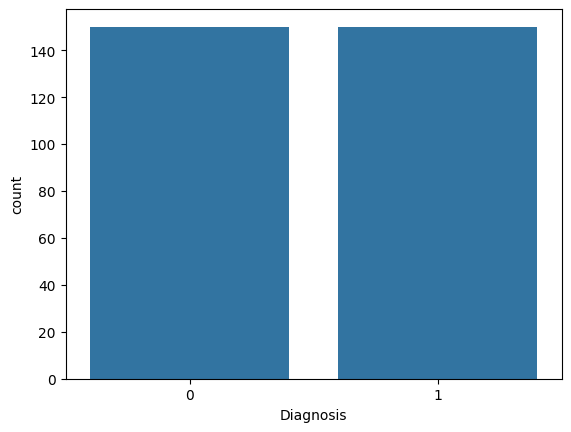

In [ ]:
#checking the class imbalance using the target variable  which is the (diagnosis)
print(dataset['Diagnosis'].value_counts())

sns.countplot(x='Diagnosis', data= dataset)
plt.show()

There is no imbalance in the dataset as the bar graph shows the diagnosis with 0 is equal to the diagnosis with the 1 showing equality

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             300 non-null    int64  
 1   Age                    300 non-null    int64  
 2   BMI                    300 non-null    float64
 3   Blood_Pressure         300 non-null    int64  
 4   Glucose_Level          300 non-null    int64  
 5   Cholesterol            300 non-null    int64  
 6   Heart_Rate             300 non-null    int64  
 7   Family_History         300 non-null    int64  
 8   Diagnosis              300 non-null    int64  
 9   Smoking_Status_Former  300 non-null    bool   
 10  Smoking_Status_Never   300 non-null    bool   
dtypes: bool(2), float64(1), int64(8)
memory usage: 21.8 KB


In [ ]:
#separating the dependent and independent features the x and y
x = dataset.drop('Diagnosis', axis=1)
y = dataset['Diagnosis']

In [ ]:
#splitting the dataset to train and test
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state = 42)


In [ ]:
#feature scaling for the SVM model
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
#training the first svm linear model
from sklearn.svm import SVC
svm_linear = SVC(kernel='linear', C=1)
svm_linear.fit(x_train, y_train)

SVC(C=1, kernel='linear')

In [ ]:
#training the second svc model using the rbf as the kernel where c =1
svm_rbf_1 = SVC(kernel='rbf', C=1)
svm_rbf_1.fit(x_train, y_train)

SVC(C=1)

In [ ]:
#training the svm model with c=10
svm_rbf_10 = SVC(kernel='rbf', C=10)
svm_rbf_10.fit(x_train, y_train)

SVC(C=10)

In [ ]:
#Creating a function to reuse for all metrics
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    return acc, prec, rec, cm

In [ ]:
results = {}

results['Linear_C1'] = evaluate_model(svm_linear, x_test, y_test)
results['RBF_C1'] = evaluate_model(svm_rbf_1, x_test, y_test)
results['RBF_C10'] = evaluate_model(svm_rbf_10, x_test, y_test)

print(results)

{'Linear_C1': (1.0, 1.0, 1.0, array([[25,  0],
       [ 0, 35]])), 'RBF_C1': (1.0, 1.0, 1.0, array([[25,  0],
       [ 0, 35]])), 'RBF_C10': (1.0, 1.0, 1.0, array([[25,  0],
       [ 0, 35]]))}


The results show that the Linear SVM performs just as well as the RBF kernel regardless of the C value. This indicates that the data is linearly separable, so the flexibility of the RBF kernel is unnecessary. Changing C from 1 to 10 had no impact, meaning the model does not overfit or underfit, as the dataset is clean, balanced, and has clear class boundaries.

All three SVM models - Linear (C=1), RBF (C=1), and RBF (C=10) - achieved perfect performance with 100% accuracy, precision, and recall. This indicates that the dataset is linearly separable, as the linear kernel performed just as well as the more flexible RBF kernel. The C parameter had no effect because the data is clean and balanced, with no overfitting observed. Based on these results, the Linear SVM with C=1 is recommended as the final model since it is simpler, faster, and fully accurate. From a medical perspective, this model ensures no sick patient is misclassified as healthy (recall = 1) and no healthy patient is misdiagnosed (precision = 1), making it reliable for clinical decision support.